In [76]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [77]:
def f(x):
    return 3*x**2 - 4*x +5

In [78]:
f(3.0)

20.0

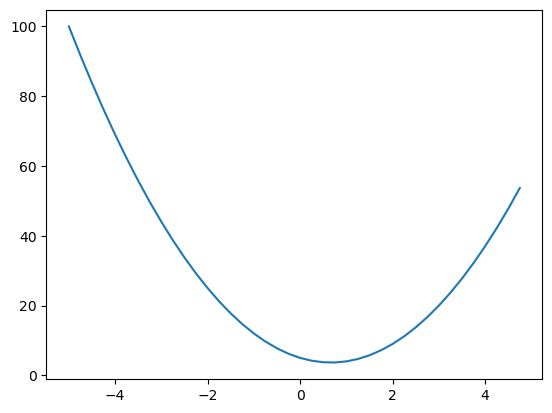

In [79]:
xs = np.arange(-5,5,0.25)
ys = f(xs)
plt.plot(xs,ys)
plt.show()

In [80]:
h = 0.000001
x = 3
(f(x+h)-f(x))/h

14.000003002223593

In [81]:
class Value:
    def __init__(self,data,_children=(),_op='',label = ''):
        self.data = data
        self.grad = 0.0
        self._prev = set(_children)
        self._backward = lambda:None
        self._op = _op
        self.label = label
        
    def __repr__(self):
        return f"value(data={self.data})"

    def __radd__(self, other):
        return self + other
        
    def __add__(self,other):
        other  = other if isinstance(other,Value) else Value(other)
        result = Value(self.data + other.data,(self,other),'+')
        def _backward():
            self.grad = 1.0 * result.grad
            other.grad = 1.0 * result.grad

        result._backward = _backward
        return result
    def __mul__(self,other):
        other  = other if isinstance(other,Value) else Value(other)
        result = Value(self.data * other.data,(self,other),'*')
        def _backward():
            self.grad = other.data * result.grad
            other.grad = self.data * result.grad

        result._backward = _backward
        return result

    def __neg__(self):
        return self * -1

    def __sub__(self, other):
        return self + (-other)

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data**other, (self,), f'**{other}')

        def _backward():
            self.grad += (other * self.data**(other-1)) * out.grad

        out._backward = _backward

        return out

    def __rmul__(self, other):  # other * self
        return self * other

    def __truediv__(self, other):
        return self * other**-1
        
    def tanh(self):
        x = self.data
        t = (math.exp(2*x)-1)/(math.exp(2*x)+1)
        out = Value(t , (self,),'tanh')
        def _backward():
            self.grad = (1 - t**2) * out.grad

        out._backward = _backward
        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self,), 'exp')

        def _backward():
            self.grad = out.data * out.grad

        out._backward = _backward

        return out

    def backward(self):

        topo = []
        visited = set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)

        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

        
a = Value(2.0,label = 'a')
b = Value(3.0,label = 'b')
c = Value(-10,label = 'c')
e = a*b;e.label = 'e'
d = e + c;d.label = 'd'
f = Value(-2.0,label = 'f')
L = d*f;L.label = 'L'
L

value(data=8.0)

In [82]:
a/b

value(data=0.6666666666666666)

In [83]:
d._prev

{value(data=-10), value(data=6.0)}

In [84]:
pip install graphviz

Note: you may need to restart the kernel to use updated packages.


In [85]:
from graphviz import Digraph

def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)
    return nodes, edges


def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})  # LR = left to right

    nodes, edges = trace(root)

    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name=uid, label="{%s| data %.4f|grad %0.4f }" % (n.label , n.data , n.grad), shape='record')

        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name=uid + n._op, label=n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

In [86]:
import shutil
print(shutil.which("dot"))

C:\Program Files\Graphviz-16.1.0-win32\bin\dot.EXE


In [87]:
import os

path = r"C:\Program Files\Graphviz-16.1.0-win32\bin\dot.exe"

print(os.path.exists(path))

True


In [88]:
import os
import shutil

os.environ["PATH"] += os.pathsep + r"C:\Program Files\Graphviz-16.1.0-win32\bin"

print(shutil.which("dot"))

C:\Program Files\Graphviz-16.1.0-win32\bin\dot.EXE


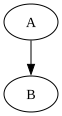

In [89]:
import graphviz

dot = graphviz.Digraph()
dot.edge("A", "B")
dot

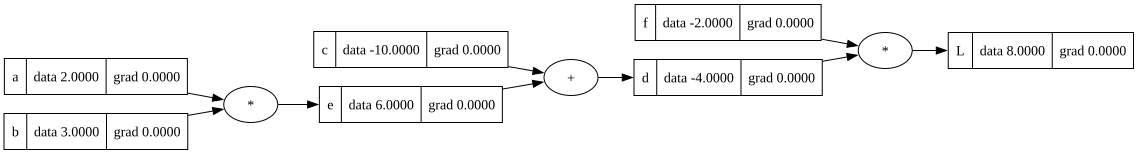

In [90]:
dot = draw_dot(L)
dot

In [91]:
L.grad = 1

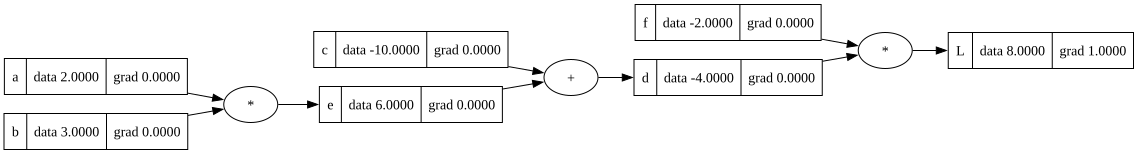

In [92]:
draw_dot(L)

In [93]:
plt.plot(np.arange(-5, 5, 0.2), np.tanh(np.arange(-5, 5, 0.2)))
plt.grid();


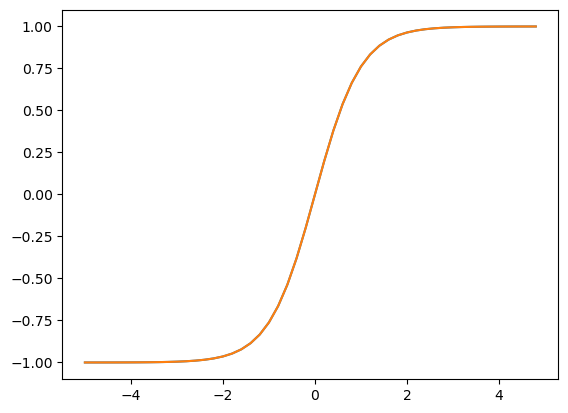

In [94]:
import numpy as np
import matplotlib.pyplot as plt

plt.plot(np.arange(-5, 5, 0.2), np.tanh(np.arange(-5, 5, 0.2)))
plt.grid()
plt.show()

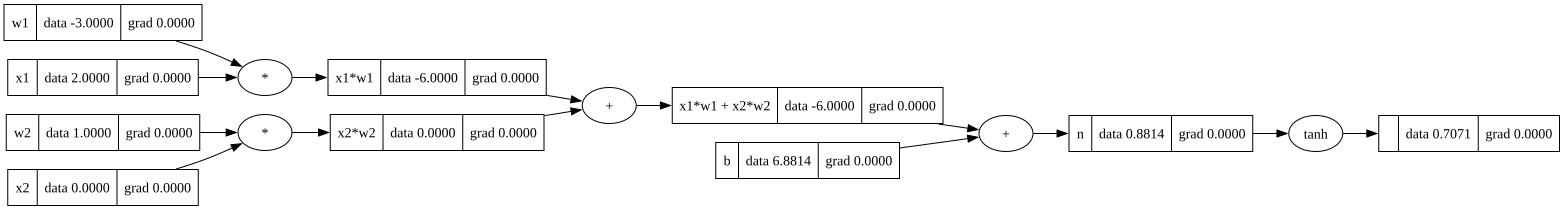

In [95]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

# bias of the neuron
b = Value(6.8813735870195432, label='b')

# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'

x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'

n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh()
draw_dot(o)

In [96]:
o.backward()

In [97]:
o.grad = 1.0
o._backward()
n._backward()

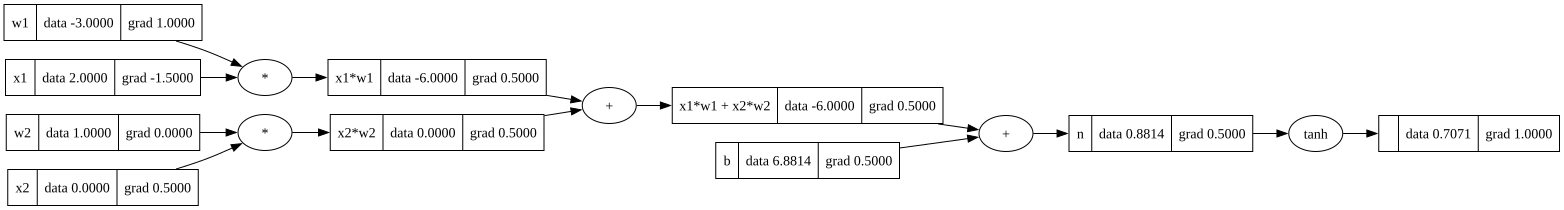

In [98]:
draw_dot(o)

In [99]:
o.grad = 1.0

In [100]:
o.backward()

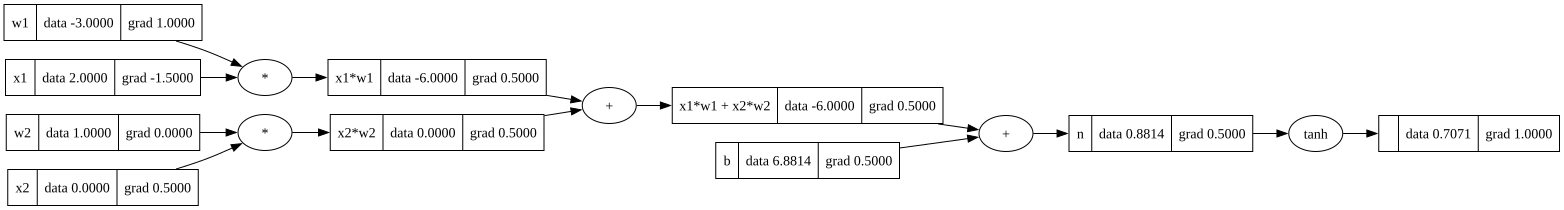

In [101]:
draw_dot(o)

In [102]:
topo = []
visited = set()

def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)

build_topo(o)
topo

[value(data=0.0),
 value(data=1.0),
 value(data=0.0),
 value(data=-3.0),
 value(data=2.0),
 value(data=-6.0),
 value(data=-6.0),
 value(data=6.881373587019543),
 value(data=0.8813735870195432),
 value(data=0.7071067811865476)]

In [103]:
o.label = 'o'

#o = tanh(n)
#do/dn = 1-o^2

In [104]:
1-o.data**2

0.4999999999999999

In [105]:
n.grad = 0.5

#plus is a gradient distributior
d(a+h)={((a+h)+b)-a+b}/h=1

In [106]:
b.grad = 0.5
x1w1x2w2.grad = 0.5

In [107]:
#again plus operator 
x1w1.grad = 0.5
x2w2.grad = 0.5

In [108]:
#multiplication operator returns the other number multipplied by the earlier derivative 
w1.grad = x1.data * x1w1.grad
x1.grad = w1.data * x1w1.grad

w2.grad = x2.data * x2w2.grad
x2.grad = w2.data * x2w2.grad

In [109]:
%pip install torch

Note: you may need to restart the kernel to use updated packages.


In [110]:
import torch

In [111]:
x1 = torch.Tensor([2.0]).double()
x2 = torch.Tensor([0.0]).double()
w1 = torch.Tensor([-3.0]).double()
w2 = torch.Tensor([1.0]).double()
b = torch.Tensor([6.8813735870195432]).double()

x1.requires_grad = True
x2.requires_grad = True
w1.requires_grad = True
w2.requires_grad = True
b.requires_grad = True

n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('---')
print('x2:', x2.grad.item())
print('w2:', w2.grad.item())
print('x1:', x1.grad.item())
print('w1:', w1.grad.item())

0.7071066904050358
---
x2: 0.5000001283844369
w2: 0.0
x1: -1.5000003851533106
w1: 1.0000002567688737


In [112]:
o.item()

0.7071066904050358

In [113]:
o


tensor([0.7071], dtype=torch.float64, grad_fn=<TanhBackward0>)

In [114]:
import random 

class Neuron:

    def __init__(self, nin):
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1, 1))

    def __call__(self,x):
        act = sum((wi * xi for wi, xi in zip(self.w, x)),self.b)
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]

class Layer:

    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:

    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

x = [2.0,3.0,-1.0]
n = MLP(3,[4,4,1])
n(x)

value(data=0.014797007864706184)

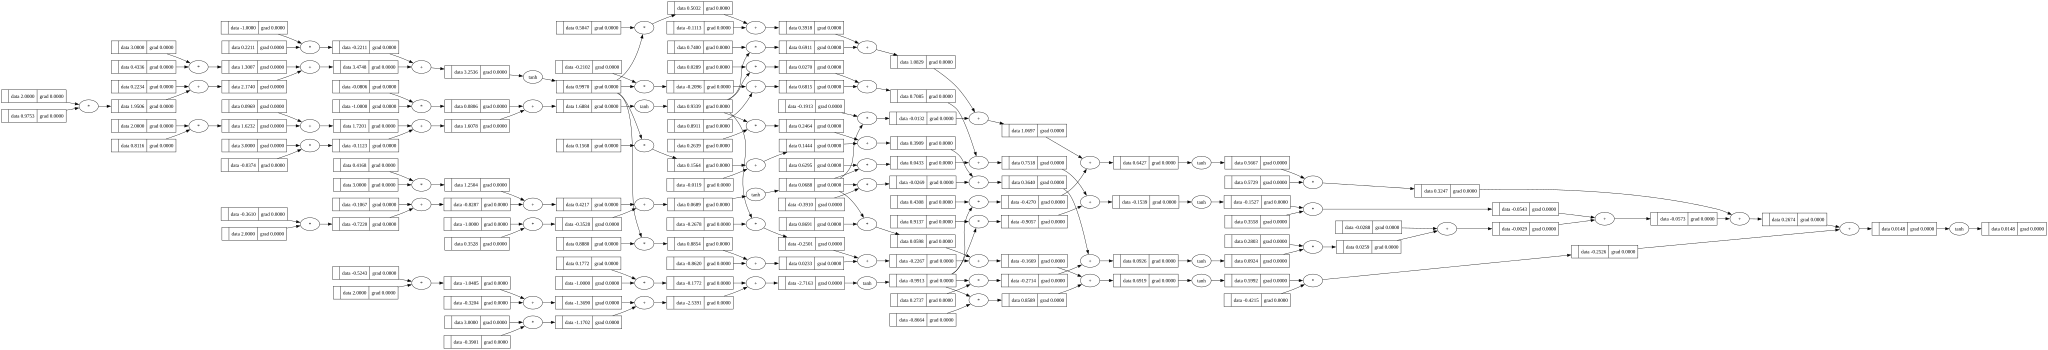

In [115]:
draw_dot(n(x))

In [116]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]

ys = [1.0, -1.0, -1.0, 1.0]  # desired targets
ypred = [n(x) for x in xs]
ypred

[value(data=0.014797007864706184),
 value(data=0.390482993744654),
 value(data=-0.07720945972427014),
 value(data=0.14988107223528616)]

In [117]:
ypred = [n(x) for x in xs]

In [118]:
loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))
loss

value(data=4.478312464171632)

In [119]:
loss.backward()

In [120]:
n.layers[0].neurons[0].w[0].grad

-0.07436121802856555

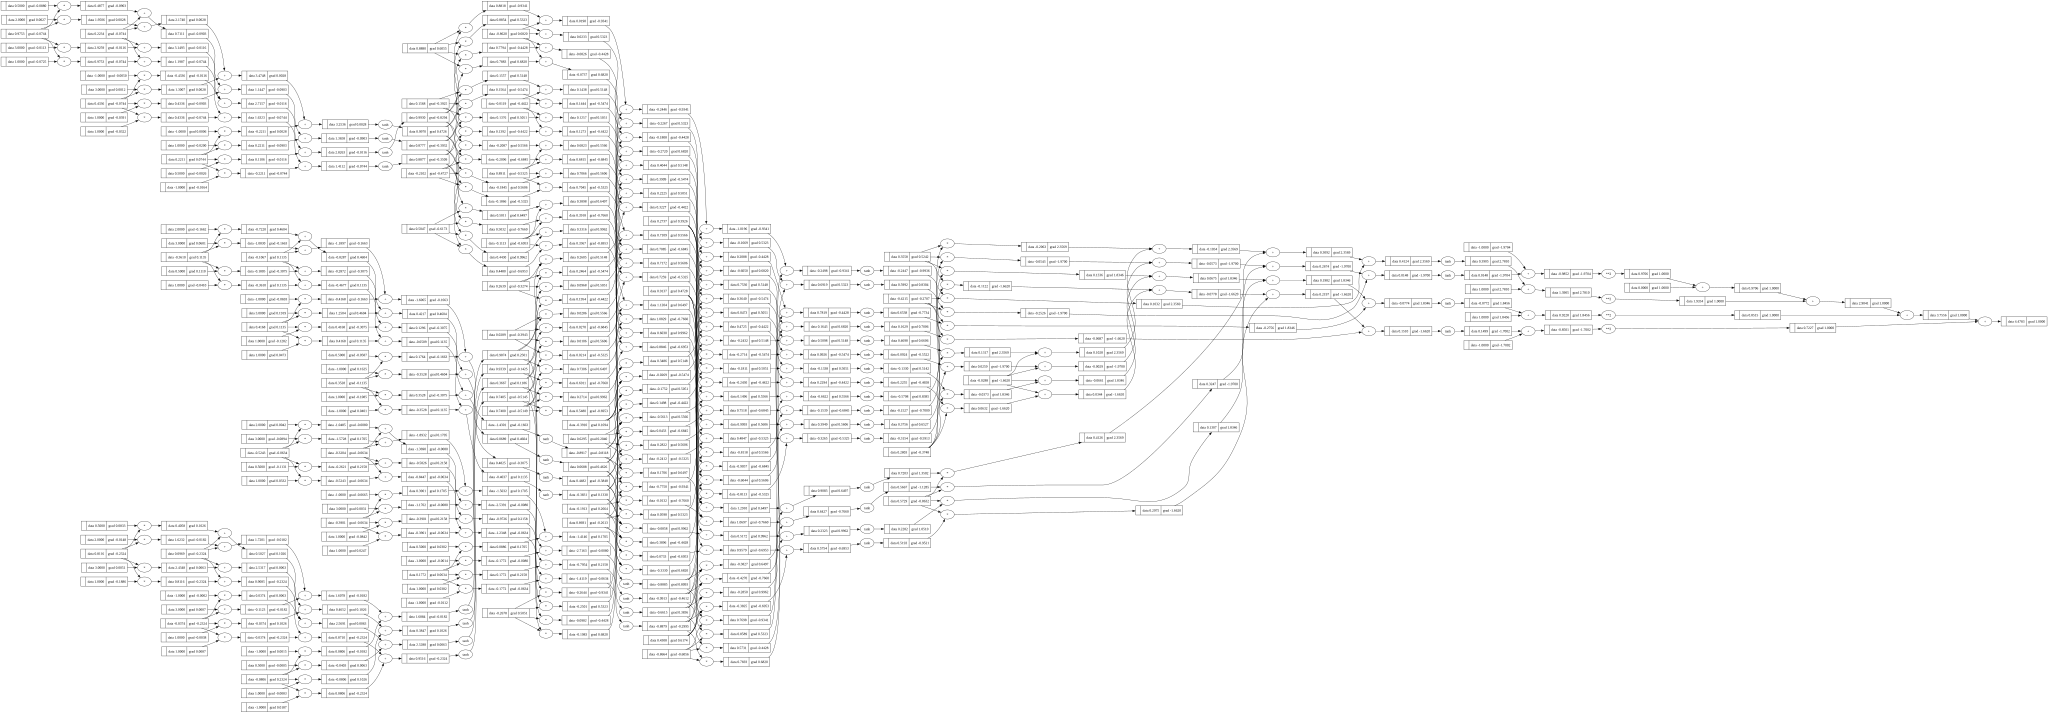

In [121]:
draw_dot(loss)

In [122]:
n.parameters()

[value(data=0.9753020714023539),
 value(data=0.4335815757145274),
 value(data=0.22112761817140503),
 value(data=0.2234227411302756),
 value(data=0.8116152182601246),
 value(data=-0.037424633524616446),
 value(data=-0.08058861651353921),
 value(data=0.09685745945187851),
 value(data=-0.36100808954639985),
 value(data=0.416802100089001),
 value(data=0.3528420012209723),
 value(data=-0.10665500664280136),
 value(data=-0.5242619238867141),
 value(data=-0.3900617419946102),
 value(data=0.17717180428972723),
 value(data=-0.32042877543683557),
 value(data=0.15682427239940444),
 value(data=0.26386837048904366),
 value(data=-0.3909742021454725),
 value(data=0.27373411951651994),
 value(data=-0.011908923195423693),
 value(data=-0.21021419023228405),
 value(data=0.02893385786244007),
 value(data=0.6294827377434684),
 value(data=0.9136888053966785),
 value(data=0.8910866701609403),
 value(data=0.5046728797985485),
 value(data=0.7399630065876912),
 value(data=-0.191326357593252),
 value(data=0.4307